In [ ]:
#hide
#skip
! [ -e /content ] && pip install -Uqq fastai  # upgrade fastai on colab

     |████████████████████████████████| 186 kB 5.3 MB/s 
     |████████████████████████████████| 56 kB 3.7 MB/s 


In [ ]:
!pip install fastbook
!pip install fastai==2.0.15
!pip install fastai2==0.0.30
!pip install fastcore==1.0.16.
!pip install fastbook --upgrade


     |████████████████████████████████| 720 kB 5.2 MB/s 
     |████████████████████████████████| 46 kB 3.4 MB/s 
     |████████████████████████████████| 1.2 MB 42.7 MB/s 
     |████████████████████████████████| 51 kB 307 kB/s 
     |████████████████████████████████| 185 kB 5.2 MB/s 
  Attempting uninstall: fastai
    Found existing installation: fastai 2.5.2
    Uninstalling fastai-2.5.2:
      Successfully uninstalled fastai-2.5.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastbook 0.0.18 requires fastai>=2.5, but you have fastai 2.0.15 which is incompatible.
     |████████████████████████████████| 179 kB 5.2 MB/s 
     |████████████████████████████████| 40 kB 3.3 MB/s 
  Attempting uninstall: fastcore
    Found existing installation: fastcore 1.3.26
    Uninstalling fastcore-1.3.26:
      Successfully uninstalled fastcore-1.3.26
ERROR: pip's dependency r

In [ ]:
import torch
import os
from fastai.vision.all import *
from fastai import *
from torchvision.models import *
import torchvision
from fastai.vision import *


In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
path = Path('/content/gdrive/MyDrive/DATASET/Spectrogram/Train')


In [ ]:
tfms = aug_transforms(flip_vert=False,size=(150,150))


In [ ]:
np.random.seed(42)
data = ImageDataLoaders.from_folder(path,test='/content/gdrive/MyDrive/DATASET/Spectrogram/Test', ds_tfms=tfms,valid_pct=0.25,bs=32,num_workers=4)

In [ ]:
learn = cnn_learner(data, resnet152 ,metrics=[accuracy,error_rate])

Downloading: "https://download.pytorch.org/models/resnet152-394f9c45.pth" to /root/.cache/torch/hub/checkpoints/resnet152-394f9c45.pth


  0%|          | 0.00/230M [00:00<?, ?B/s]

/usr/local/lib/python3.7/dist-packages/torch/nn/functional.py:718: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at  /pytorch/c10/core/TensorImpl.h:1156.)
  return torch.max_pool2d(input, kernel_size, stride, padding, dilation, ceil_mode)


In [ ]:
#learn.freeze()


In [ ]:
print(learn.summary())

Sequential (Input shape: 32)
Layer (type)         Output Shape         Param #    Trainable 
                     32 x 64 x 75 x 75   
Conv2d                                    9408       False     
BatchNorm2d                               128        True      
ReLU                                                           
MaxPool2d                                                      
Conv2d                                    4096       False     
BatchNorm2d                               128        True      
Conv2d                                    36864      False     
BatchNorm2d                               128        True      
____________________________________________________________________________
                     32 x 256 x 38 x 38  
Conv2d                                    16384      False     
BatchNorm2d                               512        True      
ReLU                                                           
__________________________________________

In [ ]:
learn.fit_one_cycle (n_epoch=20,lr_max=0.0001)

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.935113,2.213545,0.201160,0.798840,15:24
1,2.502060,1.799807,0.346764,0.653236,01:20
2,2.075460,1.525880,0.454212,0.545788,01:19
3,1.682140,1.356196,0.541819,0.458181,01:19
4,1.377591,1.110646,0.617827,0.382173,01:19
5,1.016822,0.997834,0.665446,0.334554,01:19
6,0.858834,0.860772,0.704518,0.295482,01:19
7,0.646924,0.806321,0.735653,0.264347,01:19
8,0.561078,0.725201,0.757326,0.242674,01:19
9,0.470984,0.692600,0.771673,0.228327,01:19


In [ ]:
interp = ClassificationInterpretation.from_learner(learn)


In [ ]:
interp.print_classification_report()

              precision    recall  f1-score   support

   Chahargah       0.78      0.80      0.79       574
    Homayoun       0.90      0.93      0.92       476
      Mahour       0.81      0.78      0.79       557
        Nava       0.84      0.86      0.85       377
 Rastpanjgah       0.83      0.72      0.77       425
       Segah       0.79      0.77      0.78       383
       Shour       0.76      0.83      0.79       484

    accuracy                           0.81      3276
   macro avg       0.82      0.81      0.81      3276
weighted avg       0.81      0.81      0.81      3276



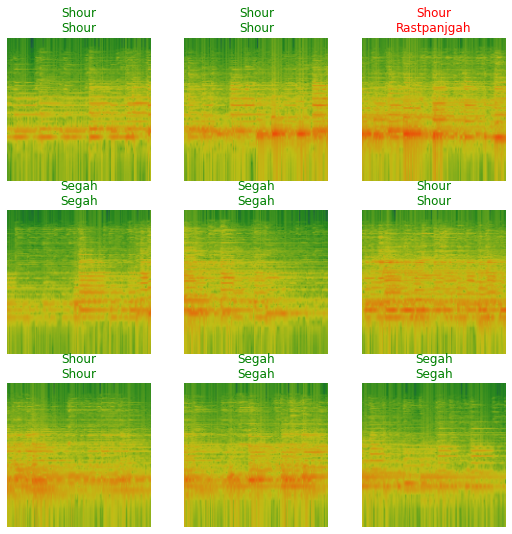

In [ ]:
learn.show_results()


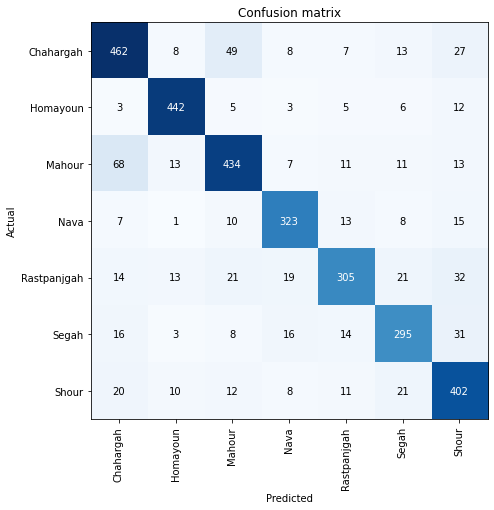

In [ ]:
interp.plot_confusion_matrix(figsize=(7,7))

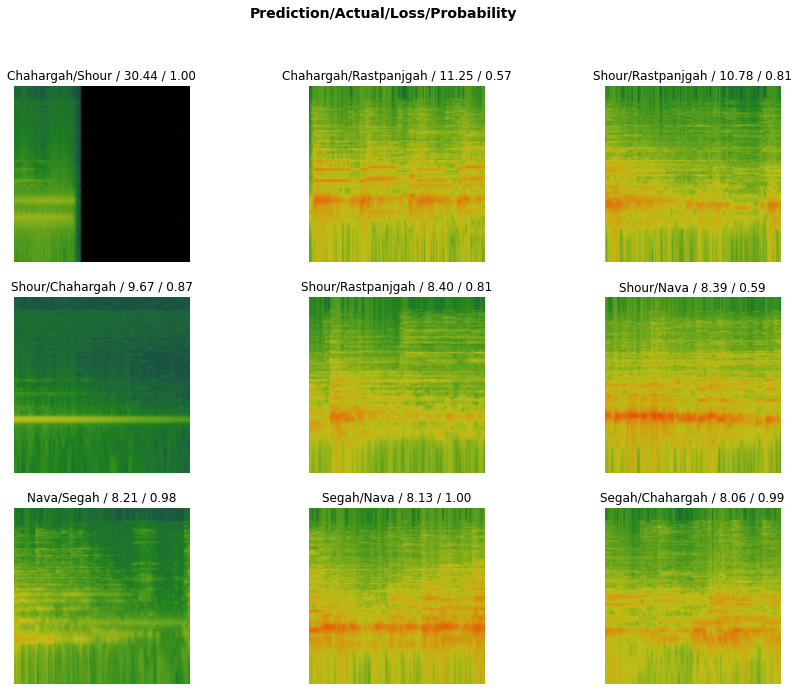

In [ ]:
interp.plot_top_losses(9, figsize=(15,11))

In [ ]:
interp.most_confused(min_val=2)


[('Mahour', 'Chahargah', 68),
 ('Chahargah', 'Mahour', 49),
 ('Rastpanjgah', 'Shour', 32),
 ('Segah', 'Shour', 31),
 ('Chahargah', 'Shour', 27),
 ('Rastpanjgah', 'Mahour', 21),
 ('Rastpanjgah', 'Segah', 21),
 ('Shour', 'Segah', 21),
 ('Shour', 'Chahargah', 20),
 ('Rastpanjgah', 'Nava', 19),
 ('Segah', 'Chahargah', 16),
 ('Segah', 'Nava', 16),
 ('Nava', 'Shour', 15),
 ('Rastpanjgah', 'Chahargah', 14),
 ('Segah', 'Rastpanjgah', 14),
 ('Chahargah', 'Segah', 13),
 ('Mahour', 'Homayoun', 13),
 ('Mahour', 'Shour', 13),
 ('Nava', 'Rastpanjgah', 13),
 ('Rastpanjgah', 'Homayoun', 13),
 ('Homayoun', 'Shour', 12),
 ('Shour', 'Mahour', 12),
 ('Mahour', 'Rastpanjgah', 11),
 ('Mahour', 'Segah', 11),
 ('Shour', 'Rastpanjgah', 11),
 ('Nava', 'Mahour', 10),
 ('Shour', 'Homayoun', 10),
 ('Chahargah', 'Homayoun', 8),
 ('Chahargah', 'Nava', 8),
 ('Nava', 'Segah', 8),
 ('Segah', 'Mahour', 8),
 ('Shour', 'Nava', 8),
 ('Chahargah', 'Rastpanjgah', 7),
 ('Mahour', 'Nava', 7),
 ('Nava', 'Chahargah', 7),
 ('Homa